# Improving the worst tetrahedron: `optimize_volume`

A tetrahedral mesh is only as good as its worst cell: one sliver — four nearly coplanar points, with a dihedral angle near 0 or 180 degrees — wrecks a finite-element stiffness matrix's conditioning. `optimize_volume` improves a tetrahedral mesh in place (same points, same boundary) by moving vertices and changing connectivity. It has two objectives:

| objective | quality | moves | guarantee |
|---|---|---|---|
| `"worst"` (default) | the least dihedral angle | guarded ODT relocation, 2-3 flips, edge removal, multi-face removal, worst-cell smoothing | the least angle never drops |
| `"energy"` | the ODT energy, flips by the least scaled Jacobian | ODT relocation, 2-3 and 3-2 flips | none on the least angle |

See `doc/optimize_volume.md`.

In [1]:
import os

# Quiet the per-sweep notes of the relocation's inversion guard.
os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
import os
import subprocess
import sys
import tempfile
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

# Renders the documentation embeds are written here as well as shown.
DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def show(img, title=None, figsize=(6, 4.5), save=None):
    """Embed a rendered RGB screenshot; with `save`, also write doc/public/images/<save>.png."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def cell_faces(mesh):
    """Per volume cell: its faces as point-id lists, over every tetra/polyhedron block."""
    out = []
    for block in mesh.cells:
        if block.type == 'tetra':
            for a, b, c, d in np.asarray(block.data):
                out.append([[b, c, d], [a, d, c], [a, b, d], [a, c, b]])
        elif block.type.startswith('polyhedron'):
            out += [[list(f) for f in cell] for cell in block.data]
    return out


def mpl_cutaway(mesh, ax, values=None, cmap='viridis', shrink=0.85, title=None):
    """Matplotlib fallback: the cells whose centroid has y < 0, each shrunk to its centroid."""
    polys, colours = [], []
    norm = plt.Normalize(*(np.nanmin(values), np.nanmax(values))) if values is not None else None
    for i, faces in enumerate(cell_faces(mesh)):
        ids = sorted({p for f in faces for p in f})
        c = mesh.points[ids].mean(axis=0)
        if c[1] >= 0:
            continue
        for f in faces:
            polys.append(c + shrink * (mesh.points[f] - c))
            colours.append(plt.get_cmap(cmap)(norm(values[i])) if values is not None else '#2ec4b6')
    ax.add_collection3d(Poly3DCollection(polys, facecolors=colours, edgecolors='#1f4e79', linewidths=0.1))
    lim = np.abs(mesh.points).max()
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim))
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=60)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def render_cutaway(mesh, title, scalars=None, cmap='viridis', save=None):
    """Cells with centroid y < 0, shrunk so each one is visible: PyVista, else matplotlib."""
    if pv is not None:
        try:
            grid = to_pyvista(mesh)
            keep = np.flatnonzero(grid.cell_centers().points[:, 1] < 0)
            part = grid.extract_cells(keep).shrink(0.85)
            pl = pv.Plotter(off_screen=True, window_size=(900, 700))
            if scalars:
                pl.add_mesh(part, scalars=scalars, cmap=cmap, show_edges=True, edge_color='#1f4e79',
                            line_width=0.3, scalar_bar_args={'title': scalars})
            else:
                pl.add_mesh(part, color='#2ec4b6', show_edges=True, edge_color='#1f4e79', line_width=0.3)
            pl.camera_position = [(2.4, 4.4, 1.8), (0, 0, 0), (0, 0, 1)]
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, save=save)
            return
        except Exception as exc:  # pragma: no cover - GL failure mid-run
            print('PyVista render skipped:', exc)
    values = None
    if scalars:
        values = np.concatenate([np.asarray(a, float).ravel() for a in mesh.cell_data[scalars]])
    fig = plt.figure(figsize=(6, 4.5))
    mpl_cutaway(mesh, fig.add_subplot(projection='3d'), values, cmap, title=title)
    plt.tight_layout()
    plt.show()


def volume(mesh):
    return mp.compute_stats(mesh)['signed_volume']


def dihedrals(mesh):
    q = mp.attach_quality(mesh).cell_data['quality:min_dihedral']
    return np.concatenate([np.asarray(a, float).ravel() for a in q])

## A mesh with slivers

The `ball` primitive maps a tetrahedral lattice onto the ball, which flattens the tetrahedra along the sphere into slivers. Rendered as a cut-away, coloured by each tetrahedron's least dihedral angle.

tetrahedra      : 10368
least angle     : 0.08 degrees
under 15 degrees: 372


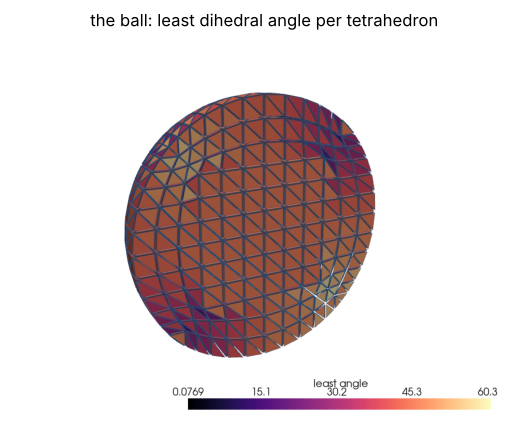

In [2]:
ball = mp.ball(n=6, cell_type='tetra')
shown = ball.copy()
shown.cell_data['least angle'] = [dihedrals(ball)]
print('tetrahedra      :', len(ball.cells[0].data))
print('least angle     : %.2f degrees' % dihedrals(ball).min())
print('under 15 degrees:', int((dihedrals(ball) < 15).sum()))
render_cutaway(shown, 'the ball: least dihedral angle per tetrahedron', scalars='least angle', cmap='magma')

## The two objectives

The energy objective lowers an energy summed over the cells, so it helps the average and leaves the extremes; the worst objective attacks the extremes directly and never makes the least angle worse.

energy least angle 0.08 -> 2.59 degrees, 60 under 15, 10380 tetrahedra
worst  least angle 0.08 -> 30.21 degrees, 0 under 15, 10351 tetrahedra
worst-objective moves: {'num_23_flips': 118, 'num_32_flips': 95, 'num_edge_removals': 1809, 'num_multi_face_removals': 730, 'num_worst_smoothed': 10217}


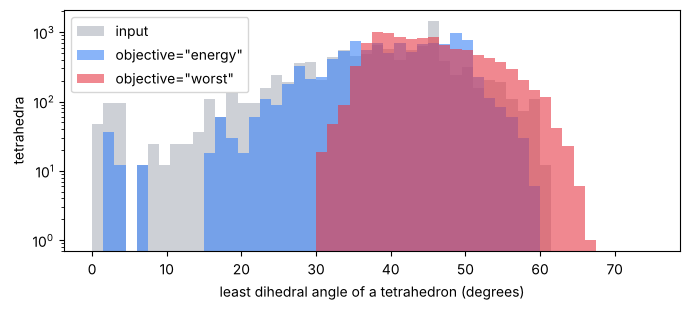

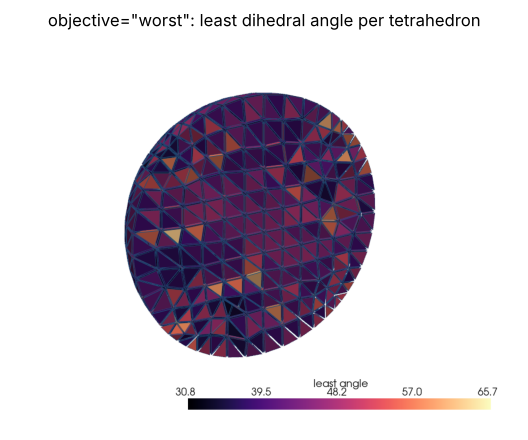

In [3]:
energy, rep_e = mp.optimize_volume(ball, objective='energy', return_report=True)
worst, rep_w = mp.optimize_volume(ball, return_report=True)
for name, rep, mesh in (('energy', rep_e, energy), ('worst', rep_w, worst)):
    d = dihedrals(mesh)
    print('%-6s least angle %.2f -> %.2f degrees, %d under 15, %d tetrahedra'
          % (name, rep['min_dihedral_before'], rep['min_dihedral_after'], (d < 15).sum(), len(d)))
print('worst-objective moves:', {k: rep_w[k] for k in ('num_23_flips', 'num_32_flips', 'num_edge_removals',
                                                       'num_multi_face_removals', 'num_worst_smoothed')})

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 75, 51)
ax.hist(dihedrals(ball), bins=bins, alpha=0.5, label='input', color='#9ca3af')
ax.hist(dihedrals(energy), bins=bins, alpha=0.6, label='objective="energy"', color='#3b82f6')
ax.hist(dihedrals(worst), bins=bins, alpha=0.6, label='objective="worst"', color='#e63946')
ax.set(xlabel='least dihedral angle of a tetrahedron (degrees)', ylabel='tetrahedra', yscale='log')
ax.legend()
plt.tight_layout()
plt.show()

worst.cell_data['least angle'] = [dihedrals(worst)]
render_cutaway(worst, 'objective="worst": least dihedral angle per tetrahedron', scalars='least angle',
               cmap='magma', save='optimize_volume_worst')

## The guarantee, step by step

Each half keeps the least angle on its own: the relocation alone (guarded, then smoothing the worst vertices), and the topological moves alone. The boundary is untouched: the same boundary triangles come out.

In [4]:
for label, kw in (('relocation only', dict(flip=False)), ('topology only', dict(relocate=False))):
    _, rep = mp.optimize_volume(ball, return_report=True, **kw)
    print('%-16s %.2f -> %.2f degrees' % (label, rep['min_dihedral_before'], rep['min_dihedral_after']))


def boundary(mesh):
    skin = mp.extract_skin(mesh)
    return {tuple(sorted(f)) for b in skin.cells for f in np.asarray(b.data).tolist()}


print('boundary unchanged:', boundary(worst) == boundary(ball))

relocation only  0.08 -> 0.47 degrees


topology only    0.08 -> 0.08 degrees


boundary unchanged: True


## Elsewhere

The CLI takes `--objective worst|energy` and `--max-ring-size K` (`meshioplusplus optimize-volume IN OUT`), the pipeline step `OptimizeVolume` takes `Objective` and `MaxRingSize`, and the C (`mio_optimize_volume_ex`), Fortran, Julia, R and WebAssembly bindings and the MCP tool report the same counters. `tools/optvol_probe.py` measures both objectives on Netgen's tetrahedra.